# Mask R-CNN

Fine-tunes a Mask R-CNN with a ResNet-50 FPN backbone on the same tile archive,
the same folds and the same crops as the two cellpose runs.

Cellpose finds objects by following a flow field to a sink. Mask R-CNN proposes
boxes first and segments inside each one, so the two differ in how an object is
separated from its neighbours, not only in the backbone.

The crops keep their 0.125 m/px, detectron2 would otherwise resize them to its
own training size. Flipping is the only augmentation, which is what the standard
recipe applies once the resizing is off.

Every fold writes `results/maskrcnn_<fold>.json` as soon as it is done, and a
fold whose file is already there is skipped.

In [1]:
import sys, os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pathlib import Path

import detectron2
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.data import DatasetCatalog, MetadataCatalog, build_detection_train_loader
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.structures import Instances, Boxes, BitMasks

warnings.filterwarnings("ignore")
root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import config
from common import tiles, crops, evaluate, folds

FOLDS = ["fold1", "fold2", "fold3", "fold4"]
BATCH = 2
ITERS = 18750                # 37500 crops, the budget of the cellpose runs
LR = 0.0025                  # the 3x default of 0.02 scaled from batch 16 to 2
CHECKPOINT_EVERY = 2500      # eight checkpoints, as in the cellpose runs
SCORE_THRESHOLD = 0.5
SAMPLE = 50                  # tiles used for the checkpoint curve
BASE = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

print("gpu:", torch.cuda.get_device_name(0))
print("detectron2:", detectron2.__version__)

gpu: Quadro RTX 5000
detectron2: 0.6


## Tiles per fold

Validation is one fold, training is everything else except the test block. The
test block stays untouched until the very end.

In [2]:
idx = pd.DataFrame(tiles.read_index())
print(idx.groupby("fold").agg(tiles=("name", "size"), boulders=("n_inner", "sum")))
print(f"\ntest block held back: {int((idx.fold == 'test').sum())} tiles")

              tiles  boulders
fold                         
always_train    382       855
fold1           286       440
fold2           192       471
fold3           207       408
fold4           186       479
test            296       471

test block held back: 296 tiles


## Crops

One crop centred on each boulder plus 30 % random corridor positions, the same
helper the cellpose notebooks use.

In [3]:
def crop_sets(fold):
    train_names = idx.loc[idx.fold.isin(folds.training_folds(fold))
                          & (idx.n_inner > 0), "name"].tolist()
    val_names = idx.loc[(idx.fold == fold) & (idx.n_inner > 0), "name"].tolist()
    xtr, ytr = crops.build(train_names, seed=0, verbose=False)
    return xtr, ytr, val_names

## What the crops look like

fold1: 3133 training crops, 150 validation tiles


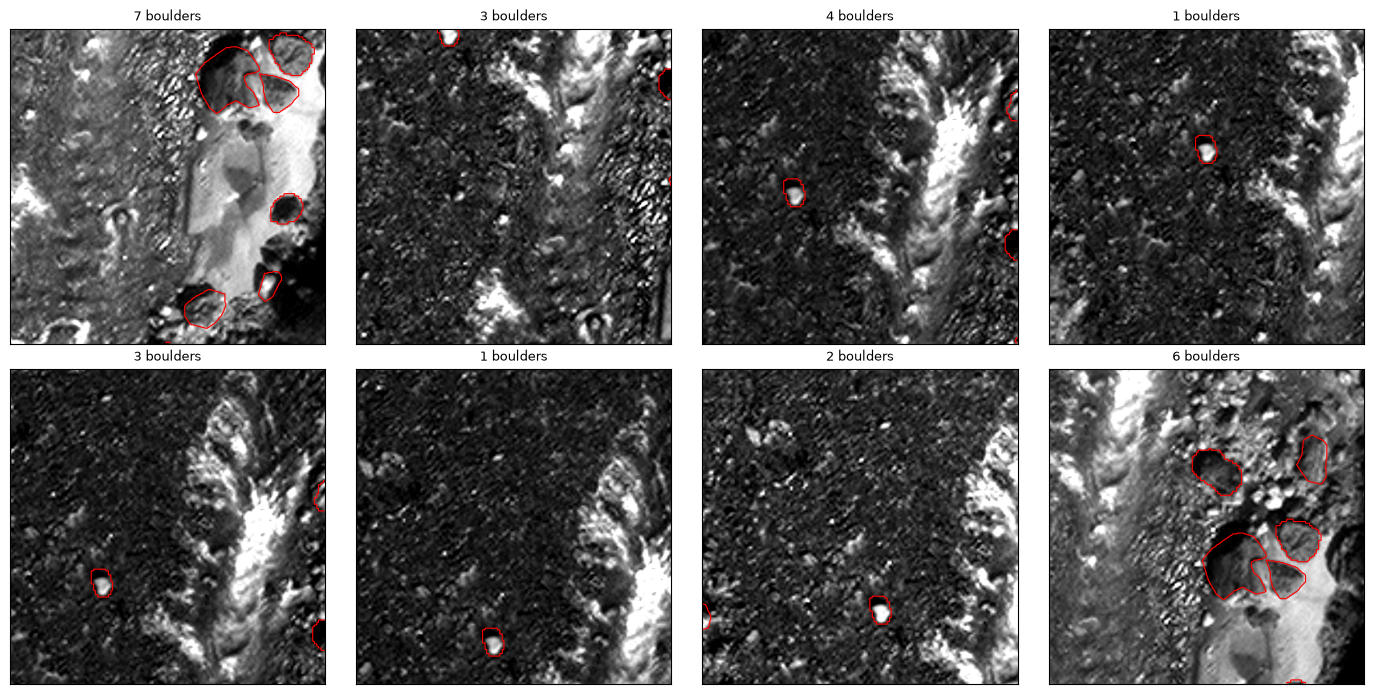

In [4]:
xtr, ytr, val_names = crop_sets(FOLDS[0])
print(f"{FOLDS[0]}: {len(xtr)} training crops, {len(val_names)} validation tiles")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (a, b) in zip(axes.ravel(), zip(xtr[:8], ytr[:8])):
    lo, hi = np.percentile(a[a > 0], config.PERCENTILE)
    ax.imshow(np.clip((a - lo) / max(hi - lo, 1), 0, 1), cmap="gray")
    ax.contour(b > 0, levels=[0.5], colors="red", linewidths=0.8)
    ax.set_title(f"{int(b.max())} boulders", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

## Feeding the crops

Detectron2 reads its images from disk. The crops live in memory, so the loader
gets a mapper of its own that stretches one band to the three the backbone
expects and turns the label raster into boxes and masks.

In [5]:
def to_bgr(image):
    """one grey band stretched to 0 to 255 and repeated three times"""
    lo, hi = np.percentile(image, config.PERCENTILE)
    grey = np.clip((image - lo) / max(hi - lo, 1e-6), 0, 1)
    return np.repeat((grey * 255).astype(np.uint8)[:, :, None], 3, axis=2)


def to_instances(label):
    ids = np.unique(label)
    ids = ids[ids > 0]
    masks = np.array([label == i for i in ids], bool).reshape(-1, *label.shape)
    boxes = []
    for mask in masks:
        ys, xs = np.nonzero(mask)
        boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])

    instances = Instances(label.shape)
    instances.gt_classes = torch.zeros(len(ids), dtype=torch.int64)
    instances.gt_boxes = Boxes(torch.as_tensor(
        np.array(boxes, np.float32).reshape(-1, 4)))
    instances.gt_masks = BitMasks(torch.as_tensor(masks))
    return instances


def mapper(record):
    image, label = CROPS[record["index"]], LABELS[record["index"]]
    if np.random.random() < 0.5:
        image, label = np.flip(image, 1), np.flip(label, 1)
    if np.random.random() < 0.5:
        image, label = np.flip(image, 0), np.flip(label, 0)
    image, label = np.ascontiguousarray(image), np.ascontiguousarray(label)

    return {"image": torch.as_tensor(to_bgr(image).transpose(2, 0, 1).copy()),
            "instances": to_instances(label),
            "height": label.shape[0], "width": label.shape[1]}


class Trainer(DefaultTrainer):
    @classmethod
    def build_train_loader(cls, cfg):
        return build_detection_train_loader(cfg, mapper=mapper)

## Train and score

Checkpoints every 2500 iterations. All of them get scored on a sample of the
validation tiles and the best one is then scored on all of them.

Scoring runs on whole tiles, not crops, because that is how it gets applied.
Only objects whose centre falls inside the corridor and inside the tile's own
inner region count, so nothing is scored twice and nothing on ground that was
never inspected.

In [6]:
def build_config(fold, size):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(BASE))
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(BASE)
    cfg.DATASETS.TRAIN = (fold,)
    cfg.DATASETS.TEST = ()
    cfg.DATALOADER.NUM_WORKERS = 4
    cfg.SOLVER.IMS_PER_BATCH = BATCH
    cfg.SOLVER.BASE_LR = LR
    cfg.SOLVER.MAX_ITER = ITERS
    cfg.SOLVER.STEPS = (int(0.7 * ITERS), int(0.9 * ITERS))
    cfg.SOLVER.CHECKPOINT_PERIOD = CHECKPOINT_EVERY
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESHOLD
    cfg.INPUT.MIN_SIZE_TRAIN = (size,)   # no resizing, the crops keep 0.125 m/px
    cfg.INPUT.MAX_SIZE_TRAIN = size
    cfg.INPUT.MIN_SIZE_TEST = 0
    cfg.OUTPUT_DIR = str(config.MODELS / f"maskrcnn_{fold}")
    return cfg


def train_fold(fold, images, labels):
    global CROPS, LABELS
    CROPS, LABELS = images, labels
    if fold in DatasetCatalog.list():
        DatasetCatalog.remove(fold)
    DatasetCatalog.register(fold, lambda: [{"index": i} for i in range(len(images))])
    MetadataCatalog.get(fold).set(thing_classes=["boulder"])

    cfg = build_config(fold, crops.SIZE)
    os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
    trainer = Trainer(cfg)
    trainer.resume_or_load(resume=False)
    trainer.train()

    # detectron2 writes one json object per line while it trains
    metrics = Path(cfg.OUTPUT_DIR) / "metrics.json"
    rows = [json.loads(line) for line in metrics.read_text().splitlines() if line.strip()]
    steps = [(r["iteration"], r["total_loss"]) for r in rows if "total_loss" in r]
    return cfg, [s[0] for s in steps], [s[1] for s in steps]

In [7]:
def to_labels(instances, shape):
    """instance masks as one raster, the higher scoring object wins an overlap"""
    if len(instances) == 0:
        return np.zeros(shape, np.uint16)
    masks = instances.pred_masks.numpy()
    labels = np.zeros(shape, np.uint16)
    for new_id, i in enumerate(np.argsort(-instances.scores.numpy()), start=1):
        labels[masks[i] & (labels == 0)] = new_id
    return labels


def predict_tile(predictor, name):
    img, true, valid = crops.read_tile(name)
    out = predictor(to_bgr(img))["instances"].to("cpu")
    keep = valid.astype(bool) & evaluate.inner_mask(img.shape)
    return (evaluate.restrict(to_labels(out, img.shape), keep),
            evaluate.restrict(true, keep))


def score_checkpoint(cfg, weights, names):
    cfg = cfg.clone()
    cfg.MODEL.WEIGHTS = str(weights)
    predictor = DefaultPredictor(cfg)
    rows = [evaluate.score(*predict_tile(predictor, n)) for n in names]
    del predictor
    torch.cuda.empty_cache()
    return evaluate.summarise(rows)

In [8]:
config.RESULTS.mkdir(parents=True, exist_ok=True)
started = time.time()

for fold in FOLDS:
    print(f"\n=== {fold} ===", flush=True)
    done = config.RESULTS / f"maskrcnn_{fold}.json"
    if done.exists():
        print("already scored, skipped", flush=True)
        continue

    t0 = time.time()
    if fold == FOLDS[0]:
        a, b, names = xtr, ytr, val_names
    else:
        a, b, names = crop_sets(fold)
    print(f"{len(a)} training crops, {len(names)} validation tiles", flush=True)

    cfg, steps, train_loss = train_fold(fold, a, b)
    print(f"trained in {(time.time() - t0) / 3600:.2f} h", flush=True)

    # the index runs scene by scene, so the sample has to step through it
    sample = names[:: max(1, len(names) // SAMPLE)][:SAMPLE]
    curve = []
    for ck in sorted(Path(cfg.OUTPUT_DIR).glob("model_*.pth")):
        s = score_checkpoint(cfg, ck, sample)
        s["checkpoint"] = ck.stem
        curve.append(s)
        print(f"  {ck.stem:28} AP {s['ap']:.3f}  P {s['precision']:.3f}  "
              f"R {s['recall']:.3f}", flush=True)

    best = max(curve, key=lambda s: s["ap"])["checkpoint"]
    final = score_checkpoint(cfg, Path(cfg.OUTPUT_DIR) / f"{best}.pth", names)
    print(f"  best {best}: AP {final['ap']:.3f} on all {len(names)} tiles", flush=True)

    json.dump(dict(model="maskrcnn", fold=fold, base=BASE,
                   iters=ITERS, batch=BATCH, lr=LR, res=config.RES,
                   crop=crops.SIZE, score_threshold=SCORE_THRESHOLD,
                   n_train_crops=len(a), n_val_tiles=len(names),
                   best_checkpoint=best,
                   hours=round((time.time() - t0) / 3600, 2),
                   step=steps, train_loss=train_loss, curve=curve, **final),
              open(done, "w"), indent=1)

print(f"\nall folds done in {(time.time() - started) / 3600:.1f} h")


=== fold1 ===


3133 training crops, 150 validation tiles


[10/19 00:20:43 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

[10/19 00:20:43 d2.data.build]: Using training sampler TrainingSampler


[10/19 00:20:43 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>


...

[10/19 03:13:07 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /DATA/schrepel/trishuli_daten/models/maskrcnn_fold4/model_final.pth ...


  model_final                  AP 0.498  P 0.588  R 0.766


[10/19 03:13:15 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /DATA/schrepel/trishuli_daten/models/maskrcnn_fold4/model_0014999.pth ...


  best model_0014999: AP 0.534 on all 116 tiles



all folds done in 2.9 h


## Results

Every boulder in the four folds was predicted exactly once, by a model that
never saw it. The pooled numbers add up TP, FP and FN across the folds rather
than averaging the APs, which would give small folds too much weight.

In [9]:
runs = [json.loads(f.read_text()) for f in
        sorted(config.RESULTS.glob("maskrcnn_fold*.json"))]

keep = ["fold", "tp", "fp", "fn", "ap", "precision", "recall", "mean_iou",
        "d50_pred", "d50_true", "d84_pred", "d84_true", "size_bias", "hours"]
per_fold = pd.DataFrame([{k: r[k] for k in keep} for r in runs]).set_index("fold")

tp, fp, fn = (int(per_fold[c].sum()) for c in ("tp", "fp", "fn"))
dp = np.concatenate([r["d_pred"] for r in runs])
dt = np.concatenate([r["d_true"] for r in runs])

per_fold.loc["pooled"] = {
    "tp": tp, "fp": fp, "fn": fn,
    "ap": tp / (tp + fp + fn),
    "precision": tp / (tp + fp),
    "recall": tp / (tp + fn),
    "mean_iou": np.average(per_fold.mean_iou, weights=per_fold.tp),
    "d50_pred": np.median(dp), "d84_pred": np.percentile(dp, 84),
    "d50_true": np.median(dt), "d84_true": np.percentile(dt, 84),
    "size_bias": np.average(per_fold.size_bias, weights=per_fold.tp),
    "hours": per_fold["hours"].sum()}
per_fold.round(3)

,tp,fp,fn,ap,precision,recall,mean_iou,d50_pred,d50_true,d84_pred,d84_true,size_bias,hours
fold,,,,,,,,,,,,,
fold1,308,155,129,0.520,0.665,0.705,0.770,4.196,4.354,5.319,5.601,-0.152,0.74
fold2,343,144,128,0.558,0.704,0.728,0.794,4.637,4.896,6.538,6.631,0.019,0.69
fold3,315,280,89,0.461,0.529,0.780,0.786,4.248,4.523,5.433,6.069,-0.174,0.74
fold4,379,232,99,0.534,0.620,0.793,0.779,4.489,4.598,5.825,6.227,-0.031,0.71
pooled,1345,811,445,0.517,0.624,0.751,0.782,4.370,4.599,5.736,6.106,-0.079,2.88


In [10]:
ap = per_fold.ap.drop("pooled")
print(f"AP per fold {ap.min():.3f} to {ap.max():.3f}, pooled {per_fold.ap['pooled']:.3f}")
print(f"precision {per_fold.precision['pooled']:.3f}, "
      f"recall {per_fold.recall['pooled']:.3f}, "
      f"mean IoU {per_fold.mean_iou['pooled']:.3f}")
print(f"D50 {per_fold.d50_pred['pooled']:.2f} m predicted against "
      f"{per_fold.d50_true['pooled']:.2f} m mapped, "
      f"bias {per_fold.size_bias['pooled']:+.2f} m")

AP per fold 0.461 to 0.558, pooled 0.517
precision 0.624, recall 0.751, mean IoU 0.782
D50 4.37 m predicted against 4.60 m mapped, bias -0.08 m


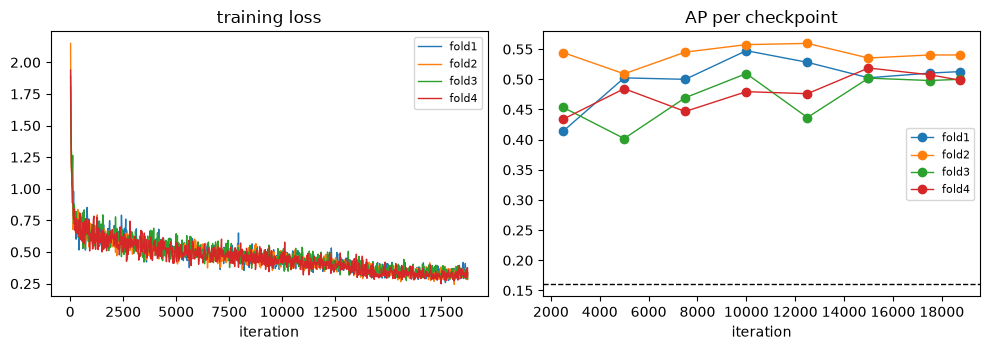

In [11]:
# the final model carries no iteration in its name
def iteration_of(checkpoint):
    tail = checkpoint.rsplit("_", 1)[-1]
    return int(tail) if tail.isdigit() else ITERS


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

for r in runs:
    axes[0].plot(r["step"], r["train_loss"], lw=1, label=r["fold"])
    curve = sorted(r["curve"], key=lambda c: iteration_of(c["checkpoint"]))
    axes[1].plot([iteration_of(c["checkpoint"]) for c in curve],
                 [c["ap"] for c in curve], "o-", lw=1, label=r["fold"])

axes[0].set_title("training loss")
axes[1].set_title("AP per checkpoint")
axes[1].axhline(0.16, color="k", ls="--", lw=1)
for ax in axes:
    ax.set_xlabel("iteration")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

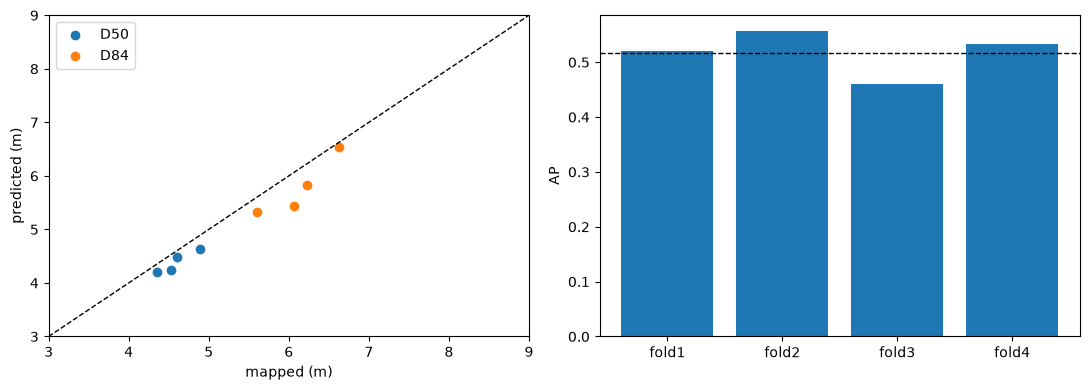

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(per_fold.d50_true.drop("pooled"), per_fold.d50_pred.drop("pooled"),
                label="D50")
axes[0].scatter(per_fold.d84_true.drop("pooled"), per_fold.d84_pred.drop("pooled"),
                label="D84")
lim = [3, 9]
axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlim(lim)
axes[0].set_ylim(lim)
axes[0].set_xlabel("mapped (m)")
axes[0].set_ylabel("predicted (m)")
axes[0].legend()

axes[1].bar(ap.index, ap.values)
axes[1].axhline(per_fold.ap["pooled"], color="k", ls="--", lw=1)
axes[1].set_ylabel("AP")
plt.tight_layout()
plt.show()

## Predictions against the hand drawn outlines

Red is drawn by hand, green is predicted, orange is the inner region. Only
objects whose centre falls inside it are counted here, the ones in the border
strip belong to the neighbouring tile.

[10/19 03:13:35 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /DATA/schrepel/trishuli_daten/models/maskrcnn_fold1/model_0009999.pth ...


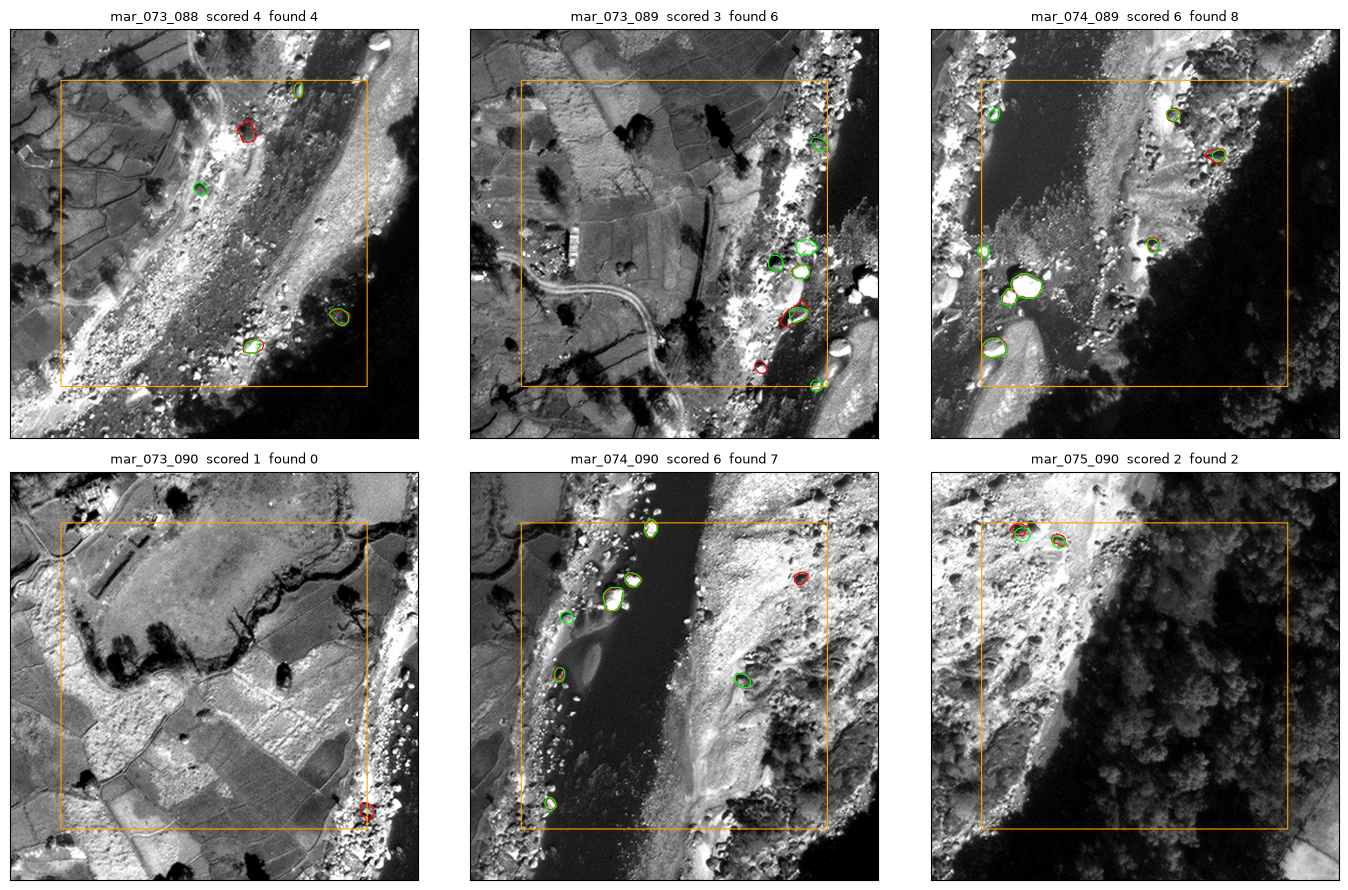

In [13]:
cfg = build_config(FOLDS[0], crops.SIZE)
cfg.MODEL.WEIGHTS = str(config.MODELS / f"maskrcnn_{FOLDS[0]}"
                        / f"{runs[0]['best_checkpoint']}.pth")
predictor = DefaultPredictor(cfg)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, name in zip(axes.ravel(), val_names[:6]):
    img, _, _ = crops.read_tile(name)
    p, t = predict_tile(predictor, name)
    lo, hi = np.percentile(img[img > 0], config.PERCENTILE)
    ax.imshow(np.clip((img - lo) / max(hi - lo, 1), 0, 1), cmap="gray")
    ax.contour(t > 0, levels=[0.5], colors="red", linewidths=0.8)
    ax.contour(p > 0, levels=[0.5], colors="lime", linewidths=0.8)
    ax.contour(evaluate.inner_mask(img.shape), levels=[0.5],
               colors="orange", linewidths=0.8)
    ax.set_title(f"{name}  scored {int(t.max())}  found {int(p.max())}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()